# Hands-On Lab - 13.11.2026

The following code has been adapted from the [H2020 MULTIPLY training ](https://github.com/multiply-org/H2020_MULTIPLY_training).
All credits for this work is to the authors.

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Some-first-concepts" data-toc-modified-id="Some-first-concepts-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Some first concepts</a></span><ul class="toc-item"><li><span><a href="#A-simple-plate-model-of-leaf-optical-properties" data-toc-modified-id="A-simple-plate-model-of-leaf-optical-properties-1.1"><span class="toc-item-num">1.1&nbsp;&nbsp;</span>A simple plate model of leaf optical properties</a></span><ul class="toc-item"><li><span><a href="#An-improvement..." data-toc-modified-id="An-improvement...-1.1.1"><span class="toc-item-num">1.1.1&nbsp;&nbsp;</span>An improvement...</a></span></li></ul></li><li><span><a href="#The-PROSPECT-leaf-optical-properties-model" data-toc-modified-id="The-PROSPECT-leaf-optical-properties-model-1.2"><span class="toc-item-num">1.2&nbsp;&nbsp;</span>The PROSPECT leaf optical properties model</a></span><ul class="toc-item"><li><span><a href="#Exploring-the-input-vs-output-parameters-space-of-PROSPECT" data-toc-modified-id="Exploring-the-input-vs-output-parameters-space-of-PROSPECT-1.2.1"><span class="toc-item-num">1.2.1&nbsp;&nbsp;</span>Exploring the input vs output parameters space of PROSPECT</a></span></li><li><span><a href="#Exercises" data-toc-modified-id="Exercises-1.2.2"><span class="toc-item-num">1.2.2&nbsp;&nbsp;</span>Exercises</a></span></li></ul></li></ul></li><li><span><a href="#Exploring-the-parameter-$N$" data-toc-modified-id="Exploring-the-parameter-$N$-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Exploring the parameter $N$</a></span></li><li><span><a href="#Vegetation-indices" data-toc-modified-id="Vegetation-indices-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Vegetation indices</a></span><ul class="toc-item"><li><span><a href="#Red-edge-model-exploration" data-toc-modified-id="Red-edge-model-exploration-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>Red edge model exploration</a></span></li></ul></li></ul></div>

In [1]:
import sys
from pathlib import Path

# Adds the parent 'folder' directory based on the current working directory
sys.path.append(str(Path.cwd().parent.parent))

%load_ext autoreload
%autoreload 2

from prosail_functions import *
import numpy as np
import matplotlib.pyplot as plt
%matplotlib widget

<div style="float:right">
    <table>
    <tr>
        <td> <img src="../../figs/kcl_logo.png" alt="Drawing" style="width:54px;height:40px;"/> 
        <td> <img src="../../figs/nceo_logo.png" alt="Drawing" style="width:200px;height:40px;"/> 
        <td> <img src="../../figs/multiply_logo.png" alt="Drawing" style="width:40px;height:40px;"/>
    </tr>
    </table>
</div>

# Optical properties of leaves

**Author:** Jose Gómez-Dans (NCEO & UCL)  `jose.gomez-dans@kcl.ac.uk`

**J Gómez-Dans (NCEO & UCL)**

In order to understand the reflectance signal acquired by a passive sensor that captures the sunlight scattered by a canopy, we need to understand how the different pigments that contribute to reflectance and transmittance of leaves, as well as understanding the geometrical disposition of leaves within the canopy. We will first look at an individual leaf, and try to come up with a simple model of how reflectance and transmittance can be calculated.

We will focus on the widely used PROSPECT model by [Jacquemoud *et al*, 1990](https://www.sciencedirect.com/science/article/pii/003442579090100Z). Although other models do exist, PROSPECT is straightforward and works reasonably well.

## Some first concepts

As a flux of photons hits an object, the photons can either be absorbed by the object ($A$), scattered away ($R$), or be transmitted (=light passes through the leaf) ($T$) by the object. Conservation laws imply that the sum of absorptance, reflectance and transmittance is one:
$$
A + R + T = 1.
$$
Note that the value of these three magnitudes varies with wavelength ($\lambda$). Understanding the processes that give rise to these changes over the spectrum allows us to infer something about the leaf biochemical and structural composition.

<img src="./../../figs/leaf++struture++cuticle+mesophyll+stoma.gif" width="700" alt="Internal leaf structure diagram">

We further consider that reflectance has a surface ($R_s$) component and a component due to the multiple scattering that takes place within the leaf, $R_d$. The first component is due to the air-leaf interface and the waxy leaf surface, and is fairly important. This surface reflectance is controlled thus by the surface properties and leaf surface microtopography. It has been observed that this component is far from *Lambertian* (isotropic), exhibiting a strong *directional effect*. 

$R_d$ is mostly a consequence of air-cell wall interfaces. As a photon beam enters the leaf, it will traverse it suffering reflectance every time it encounters a discontinuity, following a unique pattern within the leaf, and either being reflected "upwards" through the leaf surface or "downwards" through the opposite surface of the leaf. These interactions are assumed to provide a reflected and transmitted fluxes that are broadly non-directional (Lambertian). The combination of $R_s$ and $R_d$ result in the observed directional and Lambertian properties of the leaf BRDF (bi-hemispherical reflectance distribution function).

The diffuse term thus is the result of photons traversing the leaf and interacting with different components of the mesophyll, and thus opens the possibiity to learn about the internal composition and structure of leaves by looking at how light is scattered by them.

We define the optical domain to lie between 400 and 2500 $nm$. The following plot shows the spectral reflectance and transmittance from a clover leaf from the LOPEX'93 database:

<img src="./../../figs/LOPEX_clover_spectrum.png" width="900" alt="Clover reflectance and Transmittance">

In the visible region (400-700nm), there is a strong absorption of radiation by green leaves (note the peak in the green region, around 550nm). If chlorophyll concentration is low, absorption in this region is lower, and therefore, reflectance increases. In the NIR plateau (700-1100nm), absorption is controlled by cellulose and lignine, but also by the multiple scattering within the leaf, and thus, to the internal structure and interfaces of refraction within leaf layers. Towards the SWIR region, we see relatively strong absorption due to water, with some very important absorption peaks around 1450, 1950 and 2500 nm. 

### A simple plate model of leaf optical properties

A simple approximation to a monocot leaf can be a plate model, where we see the leaf as a layer with a particular refraction index $n_2$. The model can be depicted as
<img src="./images/single_plate_model_2.png" width="900" alt="Single plate model of a leaf">

An incoming beam that enters the layer is partially reflected, partially transmitted and partially absorbed. The total reflectance can be calculated following the work of Airy, and after calculating an infinite summation yields

$$
R = r_{12}+\frac{t_{12}t_{21}r_{21}\tau^2}{1-r_{21}^2\tau^2},
$$

where $r_{12}$ and $t_{12}$ are the average reflectivity and transmissivity for medium 1 into medium 2 (air to leaf) (similar arguments for $r_{21}$ and $t_{21}$. $\tau$ is the fraction of light transmitted through the medium. A similar expression can be derived from the leaf transmissivity, $T$ (not shown). $r_{12}$ is calculated from Fresnel's equations for an incidence angle $\theta$ and a refractive index $n$. We note that $r_{12} = 1- t_{12}$, $r_{21} = 1- t_{21}$ and that $t_{21}=t_{12}/n$. $\tau$ is related to the absorption coefficient of the plate, $k$, as is calculated through Beer's law. This means that in order to calculate the leaf transmittance and reflectance with this simple model, we only need the refraction index $n$ and the absorption coefficient $k$.

#### An improvement...

While the model presented above was successfully tested in a number of simple leaves and found to work reasonably well, it fails to account for more general leaves that exhibit a complex internal structure (such as senescent leaves, dicots...). To this end, the single plate model was extended to having a *stack* of $N$ plates and $N-1$ air layers between them, as shown below.


<img src="./images/multilayer_plate_model.png" width="900" alt="Multilayer plate model">


The solution to this new model was due to Stokes, and one finds that $T(N)$ and $R(N)$, respectively the transmittance and reflectance of a stack of $N$ layers is given by the following relationship

$$
\frac{R(N)}{b^{N}-b^{-N}}=\frac{T(N)}{a-a^{-1}}=\frac{1}{ab^{N}-a^{-1}b^{-N}},
$$

where

$$
\begin{align}
a &=\frac{1+R^{2}(1)-T^{2}(1) + \Delta}{2R(1)}\\
b &=\frac{1-R^{2}(1)+T^{2}(1) + \Delta}{2T(1)}\\
\Delta &= \sqrt { (T^{2}(1)-R^{2}(1)-1)-4R^{2}(1)}.
\end{align}
$$

Here, $T(1)$ and $R(1)$ are the properties of a single layer, which can be calculated with a knowledge of the refraction index of the layer and the per layer absorption coefficient $k$. The latter is a summation of the weighted absorptions of the different leaf pigments.


### The PROSPECT leaf optical properties model


The PROSPECT model implements a multi-layer concept, but assuming that the number of layers $N$ is a non-integer number. PROSPECT is able to reproduce measured leaf reflectance and transmittance spectra quite well, and has found a large user community, demonstrated by an important literature. In order to parameterise the model, the initial version of PROSPECT used as input parameters
* the number of layers $N$ (remember this can be a non-integer number), 
* the chlorophyll a+b concentration $[\mu gcm^{-2}]$ and  
* the equivalent water thickness $[cm]$. 

In essence, one parameter controls the leaf internal structure, and the other two control the leaf optical properties in the visible (chlorophyll) and NIR and SWIR (water) regions. 


Given that some biochemical compounds exhibit molecular bonds (such as C-H, O-H, and N-H bonds) with absorption features in the SWIR region (e.g., cellulose, lignin, and proteins), there was initially a concerted effort to add these individual chemical contributions to the model so that, in inversion studies, specific properties like leaf carbon or nitrogen content could be directly inferred. However, because these dry matter components lack sharp, unique spectral signatures—and because broad water absorption ($C_w$) heavily masks and dominates the signal in this exact same region—attempting to isolate individual carbon or nitrogen fractions from reflectance or transmittance alone yields very limited accuracy. 

In practice, to account for these overlapping effects without breaking model stability, researchers instead developed a single, lumped specific absorption spectrum representing bulk plant structural material, adding a new input parameter to the PROSPECT model: dry matter content $C_m$ [$g\,cm^{-2}$]. This parameter represents all the solid structural carbon compounds combined: cellulose, lignin, protein, starch and sugar.

Furthermore, as applications expanded from healthy lab leaves to natural ecosystems under stress, the pigment representation was also upgraded: the original chlorophyll contribution was split into chlorophyll $a+b$ ($C_{ab}$) and carotenoids ($C_{ar}$) to track yellowing and stress, and an additional "brown pigment" ($C_{brown}$, unitless) was introduced to accurately model senescence and dead/dry leaf litter. Together, these constituents account for nearly all of the natural variation in leaf optical properties, making PROSPECT a robust and parsimonious model for simulating leaf transmittance and reflectance across diverse environments.

#### Exploring the input vs output parameters space of PROSPECT

The next section provides a hands-on exploration of how the choices in input parameters for PROSPECT affect the predictions of reflectance and transmittance. A first way to look at this is to look at the **spectral sensitivity** of the outputs. To simplify things, we consider the *single scattering albedo*, the sum of reflectance and transmittance, $\omega=\rho+\tau$. 

The following code allows you to set the PROSPECT model parameters and to look at the spectral first  derivatives of $\omega$ as a function of the parameter of interest around location $\vec{x}_{0}$, where $\vec{x}$ is a stack of PROSPECT parameters. In an equation:

$$
\vec{H}(\vec{x}_{0})=\frac{\partial \textrm{PROSPECT}}{\partial \vec{x}}\vert_{\vec{x}=\vec{x}_{0}}
$$

**Sensitivity analysis answers a critical question**: at which wavelengths does a change in a leaf parameter (like water or chlorophyll) actually cause a noticeable change in the reflectance or scattering?

#### Exercise

In the light of the plots below (and note that you may need to push numbers around a bit to get some different effects!):

* What parameters have a clear spectral response?
* Where is the spectral response located?
* What parameters have a more "stable" spectral response?
* Are there any regions of the spectrum that are particularly crowded? What would the implication here be?

List of parameters in the PROSPECT model:
- N = Number of leaf layers
- Cab = Chlorophyll a + b
- Car = Carotenoids
- Cbrown = Brown/aging pigment
- Cw = Water thickness
- Cm = Dry matter

In [2]:
r = sensitivity_prospect()

## Exploring the parameter $N$

The number of leaf layers $N$ is an important parameter that stands in for the structural complexity of the internal leaf structure. The aim of the next experiment is to see what effect $N$ has in the ratio of reflectance to transmittance of the leaves.

* Comment on the form of the relationships found. 
* Does the random variation of the other parameters seem to have much impact? 
* What is the form of the relationship you see? Does the form vary with $N$? If so, how? What is the general trend with varying $N$?

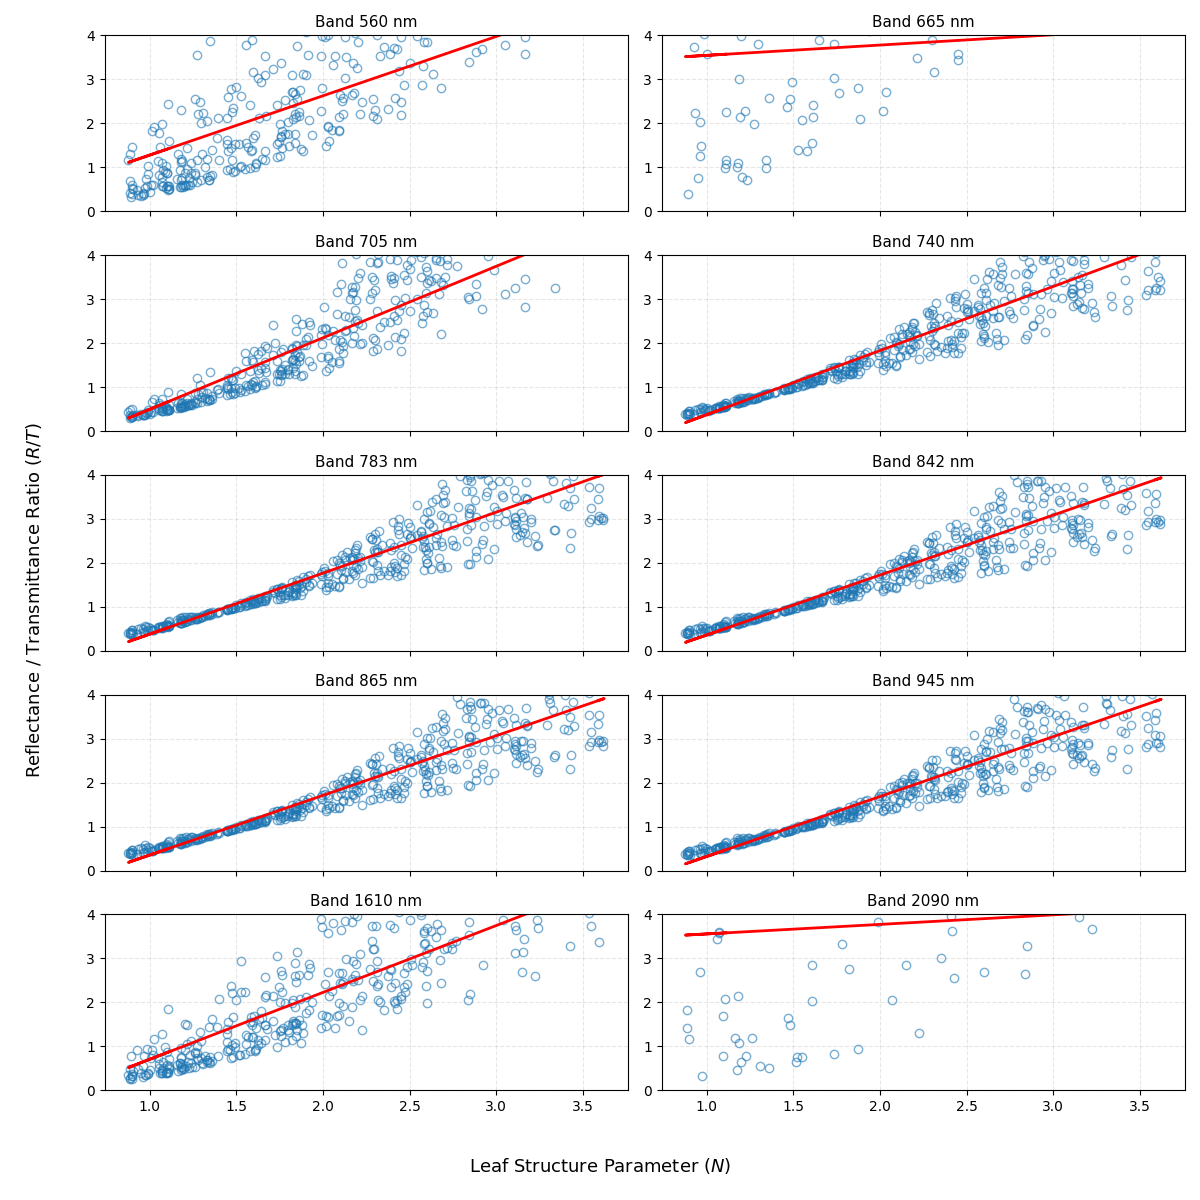

In [7]:
wv = np.arange(400, 2501)
xleafn, refl, trans = prospect_sensitivity_n(n_samples=50)

# Create the subplot grid
fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(12, 12), sharex=True)
axs = axs.flatten()

bands = [560, 665, 705, 740, 783, 842, 865, 945, 1610, 2090]

for i, band in enumerate(bands):
    # Calculate R / T ratio for this specific wavelength band
    r_t_ratio = np.mean(refl[:, wv == band] / trans[:, wv == band], axis=1)
    
    # Plot the scatter points (with slight transparency for readability)
    axs[i].plot(xleafn, r_t_ratio, 'o', markerfacecolor="none", alpha=0.6)
    
    # Clip y values for the polynomial fit
    y = np.clip(r_t_ratio, 0, 4)
    p = np.polyfit(xleafn, y, 1)
    
    # Plot the linear trend line in red
    axs[i].plot(xleafn, np.polyval(p, xleafn), '-', color='red', lw=2)
    
    axs[i].set_title(f"Band {band} nm", fontsize=11)
    axs[i].set_ylim(0, 4)
    axs[i].grid(True, linestyle='--', alpha=0.3)

# Add clean global labels for the entire grid
fig.supxlabel("Leaf Structure Parameter ($N$)", fontsize=13, y=0.02)
fig.supylabel("Reflectance / Transmittance Ratio ($R / T$)", fontsize=13, x=0.02)

# Adjust layout to make room for the outer labels
fig.tight_layout(rect=[0.03, 0.03, 1, 1])
plt.show()

## Vegetation indices

Simple ratios of reflectance at different wavelenghts have been widely used to infer the properties of leaves and canopies. The goal of these indices is to maximise the sensitivity to a particular parameter of interest, while minimising the contribution of the other parameters. A typical form for these indices is a normalised vegetation index, e.g.

$$
VI = \frac{b_2 - b_1}{b_2 + b_1 }.
$$

The ``veg_index_playground`` function allows you to calculate an index like the one above over a sweep of a parameter of interest (e.g. $C_{ab}, C_{w}, \dots$), while randomly choosing the other parameters. The script allows you to select the centre wavelength for both bands 1 and 2, as well as the bandwidth (a band extends from $\lambda_c \pm \lambda_b$). It also allows you to calculate the index using either reflectance, transmittance or SSA
* Given your analysis of the sensitivity of PROSPECT, design VIs that maximise the impact of 
    * Chlorophyll
    * Leaf water
    * Dry matter
* Comment on the robustness of the relationship
* What's the influence of spectral resolution? E.g. try to work out these indices for the typical 
spectral resolutions you find in e.g. Sentinel 2 or MODIS.

For example, if we were interested in $C_w$, we can see from above that there are some areas where $C_w$ has a strong effect on the reflectance. For example, around 1400 to 1600 nm. We can also see that its effect is quite small in the visible or NIR region. Selecting our response band to be 1610 nm (Sentinel 2 band 11), and the reference band to 865 nm (Sentinel 2 band 8), with a very narrow bandwidth (1nm), we can see what the response of the VI is. An ideal VI would provide an unique match from any VI value to the parameter of interest. 


### Reflectance vs. Transmittance vs. Single Scattering Albedo (SSA)

* **Reflectance ($R$):** The most practical because it can be measured from space. However, it is vulnerable to surface boundary effects (specular/glossy reflection from the leaf cuticle), which can bypass internal chemistry and add un-correlated noise.
* **Transmittance ($T$):** Often exhibits a cleaner, more direct exponential relationship with absorption according to the Beer-Lambert law, as all transmitted light must pass through the internal leaf structure. However, it cannot be measured via downward-looking remote sensing.
* **Single Scattering Albedo (SSA):** This represents the probability of a photon being scattered rather than absorbed during an interaction:
  $$\omega = \frac{s}{s+a}$$
  SSA isolates the pure inherent optical properties (IOPs) of the leaf tissue, **completely removing the structural macro-effects of leaf thickness and layers ($N$)**. Testing your index on SSA will give you the most perfectly robust, zero-noise 1-to-1 relationship possible, serving as a theoretical ceiling for your index design.

Mode:
- ssa: single scattering albedo
- refl: reflectance
- trans: transmittance

Parameters:
- N = Internal structure
- Cab = Chlorophyll a + b
- Car = Carotenoids
- Cbrown = Brown/aging pigment
- Cw = Water thickness
- Cm = Dry matter

The function varies the chosen *sweep_param* step-by-step across its range. For every single step, it runs multiple random samples (n_samples=50) where all other five parameters are randomized. This approach is useful to check where your index can still detect water for example despite random variations in leaf structure, chlorophyll or dry matter.
<br>

### Tip to build a solid VI

- Where is the action? ($b_1$ — The Response Band): look at the **sensitivity plot** for your target parameter. Pick a wavelength where the sensitivity curve has a big peak or deep drop. Why? This means this wavelength is highly sensitive to your parameter. When your parameter changes, this band will change with it. 

- Where is the peace and quiet? ($b_2$ — The Reference Band): look at the same sensitivity plot. Pick a wavelength where the sensitivity curve flatlines at zero, but the overall reflectance is still high (like in the NIR region). Why? This wavelength completely ignores your target parameter, but it captures overall leaf structure ($N$) and lighting changes. By putting it in the denominator, it acts as a stable anchor that cancels out background noise.

- To design an optimal Vegetation Index , you need a Response Band ($b_1$) at the target's absorption peak and a Reference Band ($b_2$) in a neutral region.

In [ ]:
_=veg_index_playground();

interactive(children=(Dropdown(description='mode', options=('ssa', 'refl', 'trans'), value='ssa'), Dropdown(de…

<details>
    <summary><i> Final step </i> </summary>

    Sentinel 2 L2A data sheet: https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a
    Sentinel 2 indices: https://clearsky.vision/knowledge/sentinel2-indices-cheatsheet

</details>

<a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/"><img alt="Creative Commons Licence" style="border-width:0" src="https://i.creativecommons.org/l/by-nc/4.0/88x31.png" /></a><br />This work is licensed under a <a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/">Creative Commons Attribution-NonCommercial 4.0 International License</a>.